# 中文文字小偵探：Colab × Gemini 實作筆記本

用中文請 Gemini 幫忙寫程式，**你負責想清楚、按執行、對答案**。

**這本筆記本怎麼用**

1. 先按左上角 **檔案 → 在雲端硬碟中儲存副本**，之後都用自己的副本（不然改了存不起來）。
2. 從上往下，一格一格按 ▶（或按 Shift+Enter）。
3. 灰色格子是程式；有表單的格子，先填右邊的空格再按 ▶。
4. 每一關做完，填一下該關的「📝 監督日誌」。

**安全三件事**：不放個資、成績、密碼｜Gemini 功能要年滿 18 歲｜分享前先 **編輯 → 清除所有輸出**

| 區段 | 你會做的事 |
|---|---|
| 開始前 | 認識介面、裝好工具、確認 Gemini 有回應 |
| 動手前 | 上傳心智圖與 IPO，自動組出 CRISP 提示 |
| 資料從哪裡來 | 建立範例資料，或換成自己的資料 |
| 第 1–8 關 | 數字數 → 斷詞 → 對答案 → 畫圖 → 情感 → 一鍵分析 → 批次摘要 → 開書考 |
| 交作業 | 打包下載成果；影片總表 |

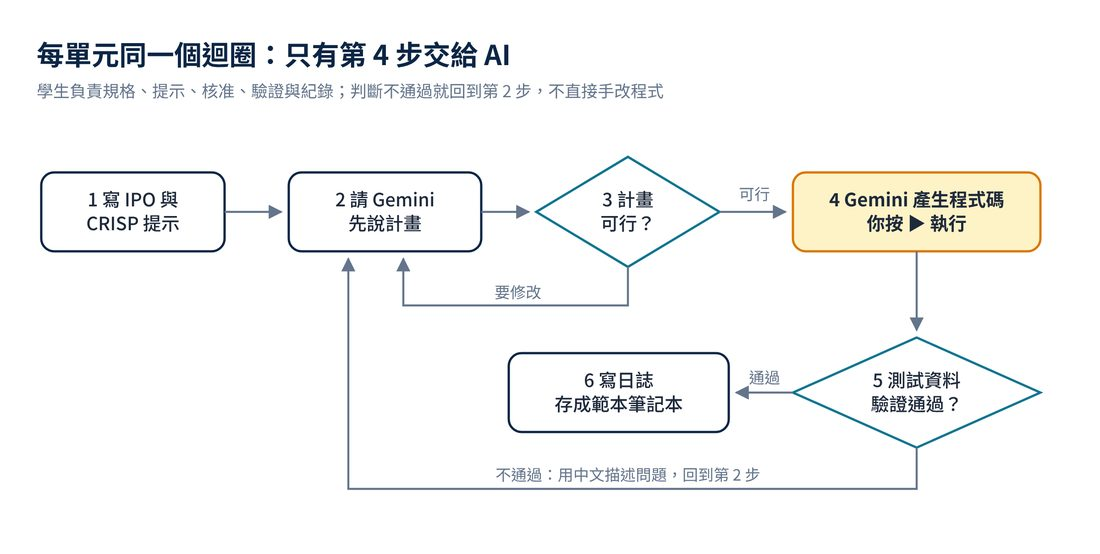

## 開始前：認識 Colab

先找到畫面上這 8 個位置，等一下都會用到。

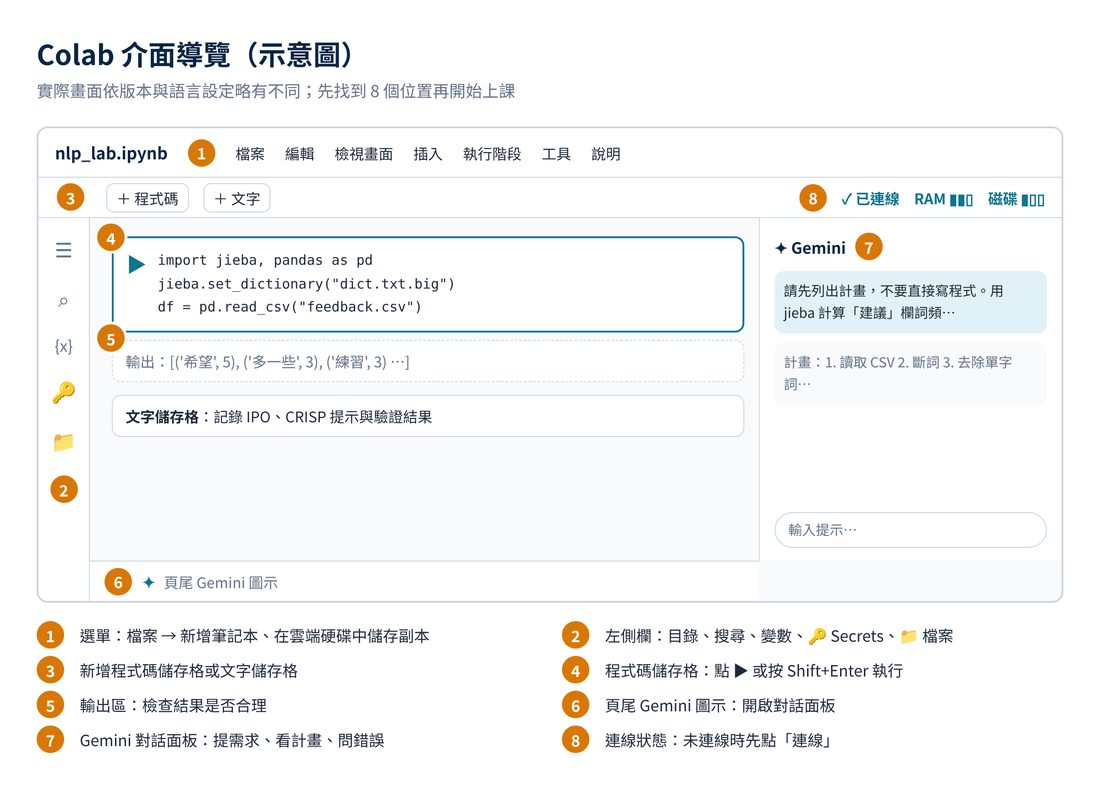

**看影片學操作**

- [V9｜Python 第一課：Google Colaboratory 介紹（DataSci Ocean）（23:40）](https://youtu.be/eJCXFIoOwdw)
  - 04:23 怎麼開啟 Colab → 跟著開一本新筆記本試試
  - 05:44 怎麼執行程式 → 回來按下面「第 0 步」的 ▶
  - 06:51 基本介面 → 對照上圖，找到 8 個位置
  - 17:33 快捷鍵 → 試試 Shift+Enter
- [V8｜Get started with Google Colaboratory（TensorFlow，英文）（3:10）](https://youtu.be/inN8seMm7UI)：跟著新增一格「程式碼」、一格「文字」
- [V3｜paul@CT&GEN AI COLAB（0:58）](https://youtu.be/l5luM0T6CfM)：看完按第 0 步的 ▶，確認工具裝好

In [ ]:
#@title 第 0 步：安裝工具（約 1–2 分鐘，只要跑一次）
!pip install -q jieba wordcloud
!wget -q -O dict.txt.big https://github.com/fxsjy/jieba/raw/master/extra_dict/dict.txt.big
!apt-get -qq update > /dev/null && apt-get -qq install -y fonts-noto-cjk > /dev/null
print("工具裝好了！")

In [ ]:
#@title 第 0 步之二：載入工具（每次重新開啟筆記本都要跑）
import re, os, json, glob
import pandas as pd
import jieba
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager
from wordcloud import WordCloud
from IPython.display import display, Image

jieba.set_dictionary("dict.txt.big")          # 繁體中文大詞典
FONT = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
font_manager.fontManager.addfont(FONT)
plt.rcParams["font.family"] = font_manager.FontProperties(fname=FONT).get_name()

GEMINI_OK = True
def ask_gemini(prompt):
    """請 Gemini 回答；不能用時回傳 None，程式不會當掉"""
    global GEMINI_OK
    if not GEMINI_OK:
        return None
    try:
        from google.colab import ai
        return ai.generate_text(prompt).strip()
    except Exception as e:
        GEMINI_OK = False
        print("目前叫不到 Gemini：", type(e).__name__)
        print("可能是帳號未滿 18 歲、這個月用量用完，或不是在 Colab 執行。")
        print("沒關係，其他關卡照常做；需要 Gemini 的地方請看老師示範。")
        return None

def write_log(unit, prompt, ai_did, decision, reason):
    """把一筆監督日誌存進 log.csv"""
    if not prompt.strip():
        print("先把「我的提示」填好，再按 ▶")
        return
    row = {"時間": pd.Timestamp.now(tz="Asia/Taipei").strftime("%m-%d %H:%M"), "關卡": unit,
           "我的提示": prompt, "AI做了什麼": ai_did, "我的決定": decision, "理由": reason}
    old = pd.read_csv("log.csv") if os.path.exists("log.csv") else pd.DataFrame()
    log = pd.concat([old, pd.DataFrame([row])], ignore_index=True)
    log.to_csv("log.csv", index=False, encoding="utf-8-sig")
    print(f"記好了，目前共 {len(log)} 筆")
    display(log.tail(3))

print("載入完成！")

### Gemini 在這本筆記本有兩種用法

- **右邊的對話面板**（點頁尾的 Gemini 星形圖示）：請它幫你寫程式、解釋錯誤。
- **程式裡呼叫**（`ask_gemini`）：讓它幫忙判斷情感、寫摘要、回答問題。用的是 Colab 內建的 `google.colab.ai`，**不用金鑰**。

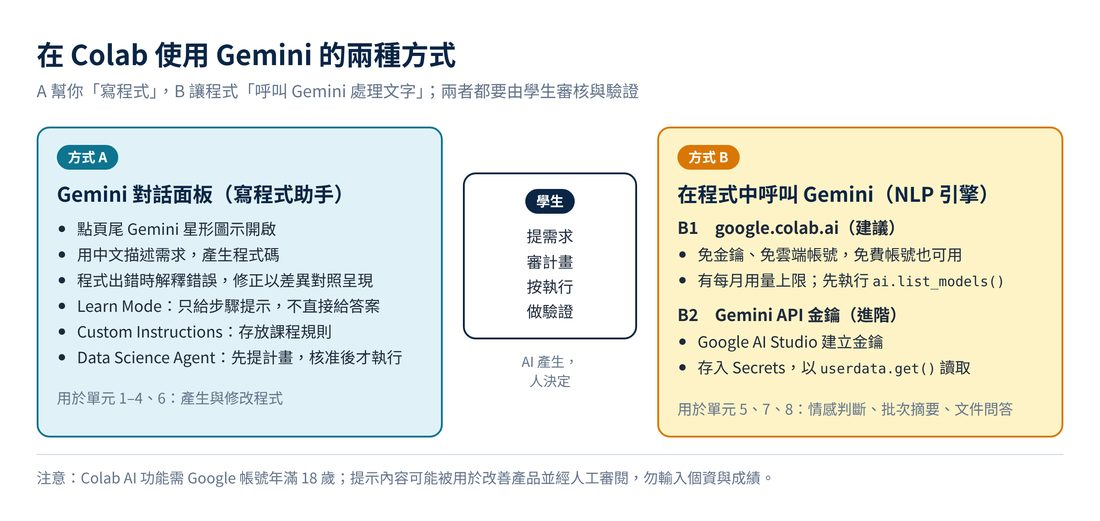

**看影片學操作**：[V10｜How to Use Google Gemini in Google Colab for FREE（Valley4Techs，英文）（4:17）](https://youtu.be/XWJzlzMaG1k)
→ 跟著打開 Gemini 面板，把第 1 關的提示卡貼進去，請它先說做法。

In [ ]:
#@title 試試看：Gemini 有回應嗎？
reply = ask_gemini("用一句繁體中文跟大一新生打招呼")
print(reply if reply else "（Gemini 這次沒回應，看上面的說明）")

## 動手前：心智圖 → IPO → CRISP 提示

先想清楚再問 AI。心智圖幫你想，IPO 幫你說清楚，CRISP 讓 Gemini 聽得懂。

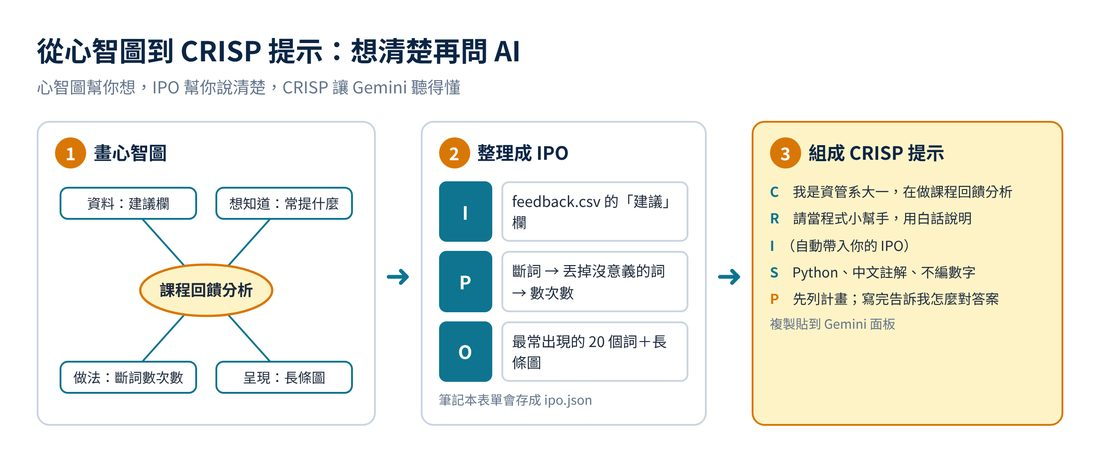

**看影片學操作**

- [V4｜心智圖 IPO 教學影片（120秒）（2:01）](https://youtu.be/RgvnGZE6dMY)：跟著畫「課程回饋分析」心智圖，拍照後用下面的上傳格交上來
- [V5｜由 IPO 架構到 Python 運作之 AI Video（0:56）](https://youtu.be/_Pda5WXIGpI)：看完把 IPO 填進下面的表單，按 ▶ 自動產生 CRISP 提示
- [V1｜先思考後驗證 120秒影音（英配雙語字幕）（1:59）](https://youtu.be/yXTW5BtXPvQ)：看完用一句話寫下「先思考」和「後驗證」各要做什麼

### 上傳你的心智圖（IPO 表照片也可以一起傳）

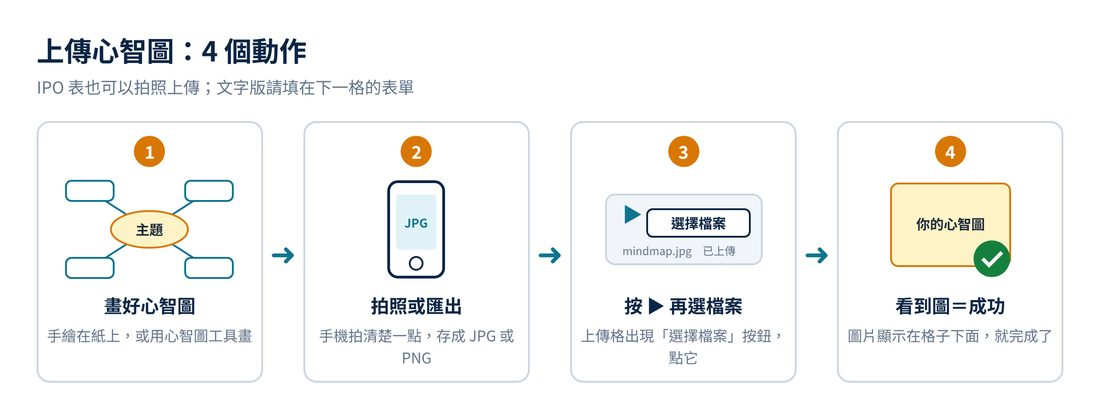

In [ ]:
#@title 上傳心智圖／IPO 表照片（按 ▶ 後點「選擇檔案」，可一次選多張）
from google.colab import files
uploaded = files.upload()
pics = [n for n in uploaded if n.lower().endswith((".png", ".jpg", ".jpeg"))]
for n in pics:
    print("收到：", n)
    display(Image(filename=n, width=600))
if not pics:
    print("還沒收到圖片。可以用手機拍下手繪的心智圖，再按一次 ▶ 上傳。")

In [ ]:
#@title 寫下你的 IPO（填右邊的格子，再按 ▶）
#@markdown **topic** 題目｜**input_I** 輸入什麼｜**process_P** 怎麼處理｜**output_O** 輸出什麼
topic = "課程回饋裡，大家最常提到什麼？" #@param {type:"string"}
input_I = "feedback.csv 的「建議」欄" #@param {type:"string"}
process_P = "斷詞 → 丟掉沒意義的詞 → 數每個詞出現幾次" #@param {type:"string"}
output_O = "最常出現的 20 個詞＋長條圖" #@param {type:"string"}

ipo = {"題目": topic, "I 輸入": input_I, "P 處理": process_P, "O 輸出": output_O}
with open("ipo.json", "w", encoding="utf-8") as f:
    json.dump(ipo, f, ensure_ascii=False, indent=1)
display(pd.DataFrame(ipo.items(), columns=["項目", "內容"]))

In [ ]:
#@title 用你的 IPO 自動組出 CRISP 提示（複製後貼到 Gemini 面板）
#@markdown **who_am_i** 我是誰｜**audience** 說給誰聽
who_am_i = "資管系大一學生" #@param {type:"string"}
audience = "同組同學" #@param {type:"string"}

crisp = f"""C 背景：我是{who_am_i}，正在做「{ipo['題目']}」。
R 角色：請當我的程式小幫手，用白話說明，讓{audience}也聽得懂。
I 任務：輸入：{ipo['I 輸入']}；處理：{ipo['P 處理']}；輸出：{ipo['O 輸出']}。
S 規格：用 Python，加中文註解；只用我給的資料，不要自己編數字。
P 驗證：先列出計畫，等我說「可以」再寫程式；寫完告訴我要怎麼檢查結果對不對。"""
print(crisp)

**CRISP 五個字母，白話版**

| 字母 | 意思 | 一句話記住 |
|---|---|---|
| C 背景 | 我是誰、在做什麼 | 先自我介紹 |
| R 角色 | AI 要扮演誰、說給誰聽 | 請它換對的身分 |
| I 任務 | 要做什麼（用 IPO 說） | 進什麼、怎麼做、出什麼 |
| S 規格 | 長什麼樣子、有什麼限制 | 給它一個範例 |
| P 驗證 | 怎麼知道它做對了 | **先想好怎麼對答案** |

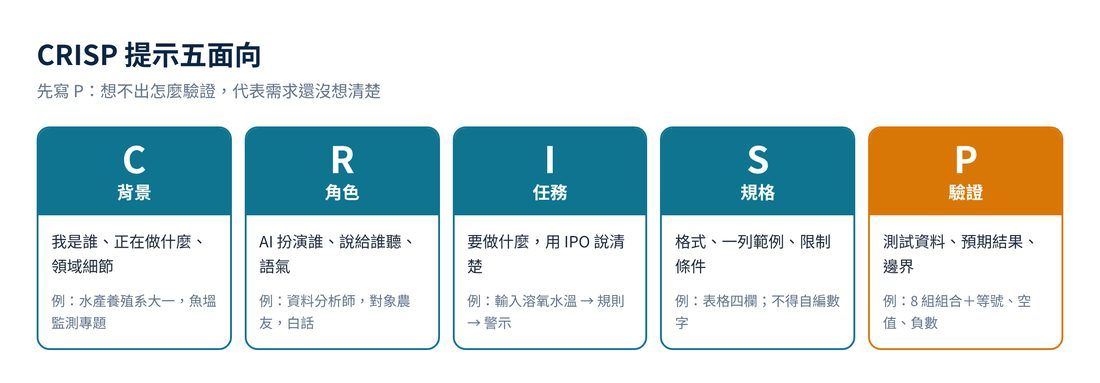

## 資料從哪裡來

這本筆記本用的資料都**由老師編寫**，是教學用的範例，不是真實的學生意見或新聞報導。

| 檔案 | 內容 | 來源 | 用在哪一關 |
|---|---|---|---|
| feedback.csv | 10 則課程建議 | 老師編寫的範例 | 第 2、3、4、6 關 |
| reviews.csv | 8 則課程評論＋人工標註 | 老師編寫的範例 | 第 5 關 |
| news.csv | 3 則農業短文 | 老師改寫的範例短文（非真實新聞） | 第 7 關 |
| docs/course_faq.txt | 課程常見問題 3 段 | 老師編寫的範例 | 第 8 關 |
| dict.txt.big | 繁體中文大詞典 | jieba 開源專案（GitHub） | 斷詞 |
| 中文字型 | Noto Sans CJK | Ubuntu 套件 fonts-noto-cjk | 圖表 |

**想換成自己的資料？**

- 用下面的「上傳自己的 CSV」格，或把檔案放在雲端硬碟再掛載。
- 可以找公開資料，例如政府資料開放平臺 [data.gov.tw](https://data.gov.tw)。
- 規則：**拿掉姓名學號等個資**、不爬別人的評論、CSV 存成 UTF-8。

In [ ]:
#@title 建立範例資料（老師編寫的教學範例）
pd.DataFrame({"id": range(1, 11), "建議": [
    "希望老師上課速度可以慢一點，範例再多一些",
    "實作課很有收穫，希望多一些Python練習",
    "投影片很清楚，但作業說明有點混亂",
    "希望期中考前有複習課",
    "Python練習太快，聽不懂迴圈",
    "上課範例很實用，期中考題目希望多一些實作",
    "作業說明可以更清楚",
    "希望每週公布練習解答",
    "分組討論很有趣，可以多一點",
    "希望範例多用生活中的資料"]}).to_csv("feedback.csv", index=False, encoding="utf-8-sig")

pd.DataFrame({"評論": [
    "老師講解很清楚，實作很有收穫", "進度太快，完全聽不懂", "還可以，普通",
    "不太好，範例很混亂", "很推薦這門課", "作業不難但有點無聊",
    "沒有想像中難懂，蠻有趣的", "上課很無聊"],
    "human_label": ["正面", "負面", "中性", "負面", "正面", "負面", "正面", "負面"]}
).to_csv("reviews.csv", index=False, encoding="utf-8-sig")

pd.DataFrame({"內文": [
    "屏東地區近日高溫多雨，芒果炭疽病發生率上升。農業單位建議農友加強果園通風並適時噴藥。",
    "石斑魚價格本週回穩。業者表示外銷訂單增加，產地價格每公斤上漲十元。",
    "颱風外圍環流預計週末影響南部。魚塭業者應提前檢查增氧機與堤岸，避免停電缺氧。"]}
).to_csv("news.csv", index=False, encoding="utf-8-sig")

os.makedirs("docs", exist_ok=True)
with open("docs/course_faq.txt", "w", encoding="utf-8") as f:
    f.write("期中考在第 9 週，範圍為單元 1 到 4。\n\n"
            "作業一律上傳 Moodle，逾期一天扣 10 分。\n\n"
            "上課地點在資管系電腦教室。")
print("範例資料建好了：", sorted(os.listdir(".")))

In [ ]:
#@title （選用）上傳自己的 CSV
from google.colab import files
mine = files.upload()
for n in mine:
    if n.lower().endswith(".csv"):
        try:
            df_mine = pd.read_csv(n)
        except UnicodeDecodeError:
            df_mine = pd.read_csv(n, encoding="cp950")   # Excel 存的 Big5 檔
        print(n, "欄位：", list(df_mine.columns))
        display(df_mine.head())

In [ ]:
#@title （選用）掛載雲端硬碟：資料放在「我的雲端硬碟/nlp-lab」
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/nlp-lab

### 關卡地圖

前面幾關用規則處理（結果可以檢查），後面幾關才請 Gemini 幫忙（結果更要檢查）。

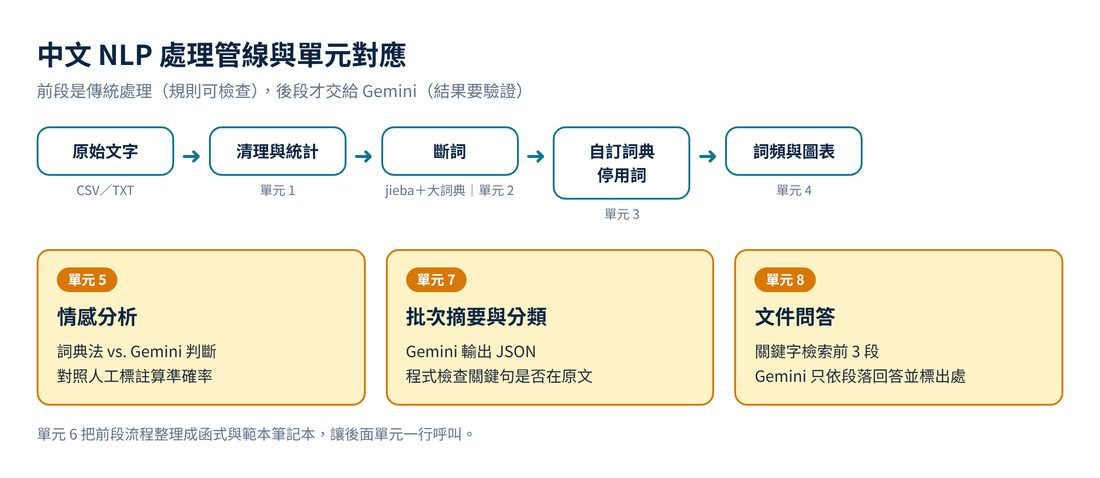

## 第 1 關｜數數看：這段話有幾個字？

**這關要做什麼**：讓程式數字數、標點和句子，再跟你自己數的比一比。

**CRISP 提示卡**（複製到 Gemini 面板）

```
C 背景：我是大一學生，第一次用 Colab。
R 角色：請當程式小幫手，用白話說明。
I 任務：幫我數一段中文的總字數（不算空白）、中文字、標點（全形半形都算）、句子（看。！？）。
S 規格：段落放在變數 text，結果印一行就好。
P 驗證：先用三行說你打算怎麼做，我說「可以」再寫程式。
```

下面是參考答案。先**自己數一次句子和標點**，填進「P 驗證」那格，再按 ▶。

In [ ]:
#@title I＋S：數字數、標點、句子
text = """屏東科技大學位於內埔。校園很大，騎腳踏車要十分鐘！你去過嗎？"""
total = len(re.sub(r"\s", "", text))                  # 去掉空白和換行
chinese = len(re.findall(r"[\u4e00-\u9fff]", text))   # 中文字
punct = len(re.findall(r"[，。！？、；：「」（）,.!?;:]", text))
sentences = len(re.findall(r"[。！？!?]", text))
print(f"總字數 {total}，中文字 {chinese}，標點 {punct}，句數 {sentences}")

In [ ]:
#@title P 驗證：跟你自己數的比一比
#@markdown **my_sentences** 我數的句數｜**my_punct** 我數的標點
my_sentences = 3 #@param {type:"integer"}
my_punct = 4 #@param {type:"integer"}
print("句數：", "一樣！" if my_sentences == sentences else f"不一樣（程式說 {sentences}），是誰的算法不同？")
print("標點：", "一樣！" if my_punct == punct else f"不一樣（程式說 {punct}），想想哪個符號沒算到")

**想一想**：把 text 換成你自己的一段話，半形的「?」有算到嗎？程式每一行你都能說出用途嗎？看不懂的那行，請 Gemini 用白話解釋。

In [ ]:
#@title 📝 監督日誌：第 1 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 1 關", my_prompt, ai_did, decision, reason)

## 第 2 關｜大家最常講什麼？

**這關要做什麼**：把每句話切成一個個詞（像把一串粽子剪開），再數哪些詞出現最多次。

**重點**：先叫 Gemini **只列計畫**，你至少改一處，再說「可以」。

**CRISP 提示卡**（也可以直接用「動手前」自動組出來的那段）

```
C 背景：feedback.csv 是課程回饋，欄位 id、建議。
R 角色：請當程式小幫手，用白話說明。
I 任務：把「建議」欄斷詞（jieba 繁體大詞典），去掉單字、標點、數字，再數次數。
S 規格：存成 freq.csv（詞, 次數），並列出前 20 名。
P 驗證：先只列計畫和要裝的套件，不要寫程式。
```

In [ ]:
#@title I＋S：斷詞、數次數
df = pd.read_csv("feedback.csv")
words = []
for t in df["建議"].dropna():
    for w in jieba.lcut(t):
        if len(w) >= 2 and not w.isdigit():   # 去掉單字、標點、數字
            words.append(w)

freq = Counter(words).most_common(20)
pd.DataFrame(freq, columns=["詞", "次數"]).to_csv(
    "freq.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(freq, columns=["詞", "次數"])

In [ ]:
#@title P 驗證：前 20 名裡，哪些詞沒什麼意義？寫下來，下一關丟掉
#@markdown **drop_words** 想丟掉的詞（用逗號隔開）
drop_words = "希望, 可以" #@param {type:"string"}
my_stop = [w.strip() for w in re.split(r"[,，、\s]+", drop_words) if w.strip()]
with open("my_stopwords.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(my_stop))
print("記下來了，第 3 關會用到：", my_stop)

**想一想**：Gemini 的計畫有沒有讀錯欄位？「老師上課」被切成一個詞，合理嗎？

In [ ]:
#@title 📝 監督日誌：第 2 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 2 關", my_prompt, ai_did, decision, reason)

## 第 3 關｜先寫標準答案，再讓程式對答案

**這關要做什麼**：標準答案由**你**寫，程式只負責對答案。AI 不能改你的答案。

### 3-A 教電腦認識新詞

「屏東科技大學」「石斑魚」這種詞，電腦常切錯。把它們加進自己的詞典，再把沒意義的詞（停用詞）丟掉。

**CRISP 提示卡**

```
C 背景：這句被切錯了：「屏東科技大學的水產養殖系研究石斑魚虹彩病毒」
I 任務：建立自訂詞典 userdict.txt 和停用詞 stopwords.txt，寫一個 seg() 函式。
S 規格：正確答案是 屏東科技大學／水產養殖系／研究／石斑魚／虹彩病毒（「的」當停用詞）。
P 驗證：用我給的正確答案寫測試，印出通過或失敗；不可以改我的答案。
```

In [ ]:
#@title 自訂詞典＋停用詞＋對答案
with open("userdict.txt", "w", encoding="utf-8") as f:
    f.write("屏東科技大學\n水產養殖系\n石斑魚\n虹彩病毒\n")
base_stop = ["的", "了", "很", "老師"]
my_stop = open("my_stopwords.txt", encoding="utf-8").read().split() if os.path.exists("my_stopwords.txt") else []
with open("stopwords.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(base_stop + my_stop))
jieba.load_userdict("userdict.txt")
stop = set(open("stopwords.txt", encoding="utf-8").read().split())

def seg(t):
    return [w for w in jieba.lcut(t) if w.strip() and w not in stop]

cases = {   # 標準答案由「人」寫，AI 不能改
    "屏東科技大學的水產養殖系研究石斑魚虹彩病毒":
        ["屏東科技大學", "水產養殖系", "研究", "石斑魚", "虹彩病毒"],
}
for s, ans in cases.items():
    got = seg(s)
    print("通過" if got == ans else "失敗", got)

### 3-B AI 說「驗證過了」，真的嗎？

我們把「魚塭水質警示」的 CRISP 提示交給 Gemini。它說 4 組測試全部一致，但仔細對照，至少有 7 個地方沒照做：

| 我們要求 | Gemini 實際做的 | 白話說 |
|---|---|---|
| 不要表格外的說明 | 寫了一大段優缺點 | 沒照格式 |
| 只用給的資料 | 自己加了時間和 30°C | 自己編資料 |
| 畫 3 mg/L 紅線 | 沒畫，也沒說做不到 | 漏掉條件 |
| 溶氧「低於」3 才開增氧機 | 3.0 自己多加「接近警戒」 | 偷改規則 |
| 列出預期結果比對 | 預期值是它自己填的 | 自己出題自己改 |
| 4 種溶氧 × 2 種水溫 | 只測 4 組，漏了 2.4＋33 | 測太少 |
| 檢查等號、空值、負數 | 只談溶氧等於 3 | 檢查不完整 |

**正確答案（照原本的規則）**：先自己填，再看下面程式裡的 expected 對不對。

| 溶氧＼水溫 | 28°C | 33°C |
|---|---|---|
| 5.2 | 正常 | 水溫過高提醒 |
| 4.0 | 正常 | 水溫過高提醒 |
| 3.0 | 正常（低於 3 才開） | 水溫過高提醒 |
| 2.4 | 開增氧機 | 開增氧機＋水溫過高提醒 |

**看影片學操作**：[V6｜Smart Aquaculture Tutorial（180s）（3:01）](https://youtu.be/O5Vdxg89dNE) → 看完把「溶氧、水溫」當 I、「警示」當 O，對照下面的 alert()。

In [ ]:
#@title 魚塭警示：規則寫成函式，用「人寫的答案」來對
def alert(do, temp):
    ok = all(isinstance(x, (int, float)) for x in (do, temp))
    if not ok or do < 0 or temp < 0:
        return "資料異常"
    msgs = []
    if do < 3:
        msgs.append("開增氧機")
    if temp > 32:
        msgs.append("水溫過高提醒")
    return "＋".join(msgs) if msgs else "正常"

expected = [   # (溶氧, 水溫, 預期結果)：這些是你寫的標準答案
    (5.2, 28, "正常"), (5.2, 33, "水溫過高提醒"),
    (4.0, 28, "正常"), (4.0, 33, "水溫過高提醒"),
    (3.0, 28, "正常"), (3.0, 33, "水溫過高提醒"),
    (2.4, 28, "開增氧機"), (2.4, 33, "開增氧機＋水溫過高提醒"),
    (3.0, 32, "正常"), (None, 30, "資料異常"), (-1, 30, "資料異常"),
]
passed = 0
for do, t, exp in expected:
    got = alert(do, t)
    passed += got == exp
    print("通過" if got == exp else "失敗", do, t, "預期", exp, "實際", got)
print(f"共 {len(expected)} 筆，通過 {passed} 筆")

**想一想**：測試通過，是程式對了，還是答案被改了？3.0 該不該警示，誰說了算？（答案：定規則的人，不是 AI）

改壞了也不用怕：**檔案 → 修訂版本記錄** 可以回到之前的版本。

In [ ]:
#@title 📝 監督日誌：第 3 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 3 關", my_prompt, ai_did, decision, reason)

## 第 4 關｜畫成圖，一眼看懂

**這關要做什麼**：把最常出現的詞畫成長條圖和文字雲。

**小實驗**：如果圖上的中文變成一個個方框，不要貼一大段程式問 Gemini，只要說「**圖上的中文都變成方框**」，看它能不能找到原因（答案：缺中文字型，第 0 步已經裝好了）。

**CRISP 提示卡**

```
I 任務：用斷好的詞畫前 15 名的橫條圖，再畫一張文字雲。
S 規格：標題「課程回饋高頻詞」，中文字型用 Noto Sans CJK。
P 驗證：告訴我怎麼確認圖上的數字是對的。
```

In [ ]:
#@title I＋S：長條圖＋文字雲（用第 3 關清理過的詞）
df = pd.read_csv("feedback.csv")
words = [w for t in df["建議"].dropna() for w in seg(t)
         if len(w) >= 2 and not w.isdigit()]
top = pd.DataFrame(Counter(words).most_common(15), columns=["詞", "次數"])

plt.figure(figsize=(8, 5))
plt.barh(top["詞"][::-1], top["次數"][::-1], color="#0E7490")
plt.title("課程回饋高頻詞（前 15 名）")
plt.xlabel("次數")
plt.tight_layout(); plt.savefig("top15.png", dpi=150); plt.show()

wc = WordCloud(font_path=FONT, background_color="white", width=800, height=400)
wc.generate_from_frequencies(dict(zip(top["詞"], top["次數"])))
wc.to_file("cloud.png")
display(Image("cloud.png"))

In [ ]:
#@title P 驗證：抽一個詞，自己數數看
#@markdown **check_word** 要檢查的詞｜**my_count** 我在 feedback.csv 數到幾次
check_word = "範例" #@param {type:"string"}
my_count = 3 #@param {type:"integer"}
program_count = dict(zip(top["詞"], top["次數"])).get(check_word, 0)
print("一樣！" if program_count == my_count else f"不一樣：程式說 {program_count} 次，回去 feedback.csv 再數一次")

**想一想**：文字雲的字大小，能拿來比較兩個詞誰多嗎？為什麼長條圖比較準？

In [ ]:
#@title 📝 監督日誌：第 4 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 4 關", my_prompt, ai_did, decision, reason)

## 第 5 關｜是稱讚還是抱怨？

**這關要做什麼**：用兩種方法判斷評論是正面、負面還是中性，再跟人工標註比比看誰比較準。

- **方法 A 詞典法**：看到「清楚、推薦」加分，看到「無聊、混亂」扣分；前面有「不、沒」就反過來。
- **方法 B 問 Gemini**：讓 Gemini 讀評論判斷。**它看不到答案**，才公平。

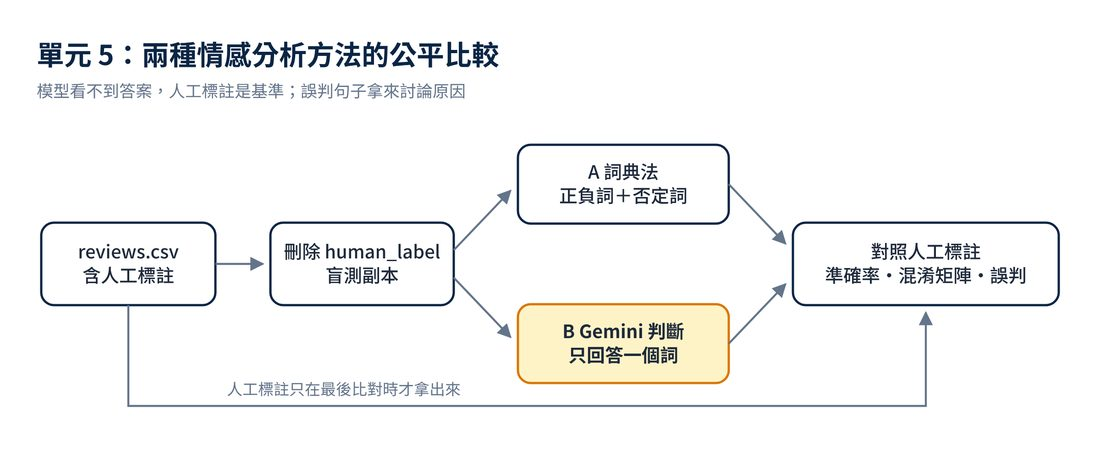

**CRISP 提示卡**

```
C 背景：reviews.csv 是課程評論，有「評論」和人工標註 human_label。
I 任務：寫詞典法函式 lexicon_label(text)，正面詞加分、負面詞扣分，要處理「不、沒、未、別」。
S 規格：回傳「正面／負面／中性」其中一個。
P 驗證：先說你會怎麼處理「不太好」和「沒有想像中難懂」，我同意再寫。
```

**看影片學操作**：[V11｜在 Google Colab 上設定 Gemini 與操作 Python（An-Wen Deng）（16:53）](https://youtu.be/mUYWpvAncjk) → 看完比較影片的寫法和這本筆記本的 `ask_gemini()`：這裡不用金鑰。

In [ ]:
#@title 方法 A：詞典法
POS = ["好", "棒", "清楚", "實用", "喜歡", "有趣", "推薦", "有收穫"]
NEG = ["差", "難懂", "無聊", "太快", "失望", "混亂", "聽不懂"]
NEGATORS = ("不", "沒", "未", "別")

def lexicon_label(text):
    score = 0
    words = jieba.lcut(text)
    for i, w in enumerate(words):
        if any(p in w for p in POS):
            s = 1
        elif any(n in w for n in NEG):
            s = -1
        else:
            s = 0
        prev = words[i-1] if i > 0 else ""          # 前一個詞
        negated = w.startswith(NEGATORS) or prev.startswith(NEGATORS)
        if s and negated and not w.startswith("聽不"):
            s = -s                                  # 遇到否定詞就反過來
        score += s
    return "正面" if score > 0 else "負面" if score < 0 else "中性"

In [ ]:
#@title 方法 B：問 Gemini（它看不到答案）＋ P 驗證：跟人工標註比
def llm_label(text):
    ans = ask_gemini("下面這則課程評論是在稱讚、抱怨，還是普通？"
                     "只回答「正面」「負面」「中性」其中一個詞。\n評論：" + text)
    return ans if ans in ("正面", "負面", "中性") else "無法判斷"

full = pd.read_csv("reviews.csv")
blind = full.drop(columns=["human_label"])     # 把答案拿掉再給 AI
blind["詞典法"] = blind["評論"].apply(lexicon_label)
blind["Gemini"] = blind["評論"].apply(llm_label)
blind["人工標註"] = full["human_label"]
for m in ["詞典法", "Gemini"]:
    if (blind[m] == "無法判斷").all():
        print(m, "這次沒有結果（Gemini 不能用），請看老師示範")
    else:
        print(m, "準確率", round((blind[m] == blind["人工標註"]).mean(), 2))
blind

**找找看**：「沒有想像中難懂，蠻有趣的」被詞典法判成**中性**。因為斷詞是「沒有／想像中／難懂／蠻／有趣」，程式只看前一個詞，「沒有」隔太遠沒作用；「難懂」扣 1、「有趣」加 1，剛好抵銷。

**想一想**：人工標註兩個人意見不同的句子，能當標準答案嗎？哪一種判錯最嚴重？

In [ ]:
#@title 📝 監督日誌：第 5 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 5 關", my_prompt, ai_did, decision, reason)

## 第 6 關｜做成「一鍵分析」

**這關要做什麼**：把第 2–4 關的步驟包成一個函式，換一份資料只要一行。

**也把規則存起來**：在 Gemini 面板打開 **Custom Instructions**，貼上下面這段，之後在這本筆記本問問題都會照規則：

```
請用繁體中文回答。我是大一學生，正在學中文 NLP（jieba 斷詞、pandas）。
收到需求時，先列出計畫與要安裝的套件，等我回覆「可以」再寫程式。
程式加上中文註解；只用我提供的資料，不要自己編數字。
不要使用舊套件 google.generativeai；呼叫 Gemini 請用 google.colab.ai。
```

想自己練習寫程式時，可以打開 **Learn Mode**：Gemini 只給提示，不直接給答案。

In [ ]:
#@title I＋S：一鍵分析函式
def analyze(csv_path, col, top_n=15):
    df = pd.read_csv(csv_path)
    words = [w for t in df[col].dropna() for w in seg(t)
             if len(w) >= 2 and not w.isdigit()]
    top = pd.DataFrame(Counter(words).most_common(top_n), columns=["詞", "次數"])
    plt.figure(figsize=(8, 5))
    plt.barh(top["詞"][::-1], top["次數"][::-1], color="#0E7490")
    plt.title(f"{csv_path}｜{col}｜高頻詞")
    plt.tight_layout(); plt.show()
    return top

analyze("feedback.csv", "建議")

In [ ]:
#@title P 驗證：換一份資料試試（例如新聞）
#@markdown **csv_file** 檔名｜**column** 要分析的欄位
csv_file = "news.csv" #@param {type:"string"}
column = "內文" #@param {type:"string"}
analyze(csv_file, column, top_n=10)

**想一想**：函式有沒有把檔名或欄位寫死？新資料套用舊的停用詞合適嗎？

**存成範本**：**編輯 → 清除所有輸出**，再 **檔案 → 在雲端硬碟中儲存副本**。

In [ ]:
#@title 📝 監督日誌：第 6 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 6 關", my_prompt, ai_did, decision, reason)

## 第 7 關｜請 Gemini 一次讀很多篇新聞

**這關要做什麼**：請 Gemini 幫每篇新聞寫摘要、分類、挑一句重點，再用程式抓出它有沒有「一本正經地瞎掰」。

**抓瞎掰的方法**：要求重點句「一字不改從原文抄」，程式就能檢查這句話是不是真的在原文裡。

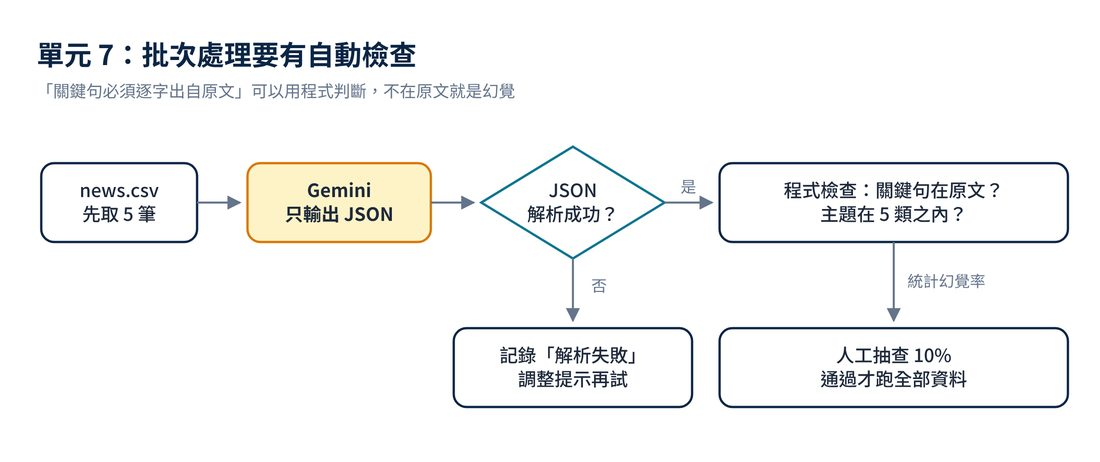

**CRISP 提示卡**（已經寫在程式的 prompt 裡）

```
I 任務：讀新聞，給我 50 字摘要、主題分類、原文中最重要的一句。
S 規格：只輸出 JSON；主題只能從「病蟲害、水產、氣候、市場、其他」選一個。
P 驗證：重點句必須一字不改出自原文。
```

**看影片學操作**

- [V7｜基於 ROUGE 指標評估生成式 AI 模型之偏差與雜訊（0:56）](https://youtu.be/glkNRqyLSio)：看完想想，除了「重點句在原文」，還能怎麼檢查摘要好不好？
- [V12｜5 分鐘在 Colab 快速使用 Gemini 來產生文本（李政軒）（8:19）](https://youtu.be/zrKyTYQqH-s)：影片用的是舊套件 `google.generativeai`，練習時改用本筆記本的寫法。

In [ ]:
#@title I＋S：批次摘要、分類、挑重點句
TOPICS = ["病蟲害", "水產", "氣候", "市場", "其他"]

def tag(text):
    raw = ask_gemini(f"""閱讀下列農業短文，只輸出 JSON，不要任何其他文字：
{{"summary": "50 字內摘要", "topic": "{'、'.join(TOPICS)} 擇一",
  "key_sentence": "一字不改摘自原文的一句"}}
短文：{text}""")
    if raw is None:
        return {"summary": "", "topic": "Gemini 不能用", "key_sentence": ""}
    raw = raw.removeprefix("```json").removesuffix("```").strip()
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        return {"summary": "", "topic": "格式不對", "key_sentence": ""}

news = pd.read_csv("news.csv")
rows = []
for text in news["內文"].head(5):        # 先跑 5 筆，看過沒問題再跑全部
    r = tag(text)
    ks = r.get("key_sentence", "")
    r["重點句在原文"] = bool(ks) and ks in text   # 不在原文＝瞎掰
    r["主題合法"] = r.get("topic") in TOPICS
    rows.append(r)
result = pd.DataFrame(rows)
result

In [ ]:
#@title P 驗證：瞎掰率是多少？
done = result[result["topic"].isin(TOPICS + ["格式不對"])]
if len(done):
    bad = (~done["重點句在原文"]).sum()
    print(f"檢查 {len(done)} 筆，重點句不在原文 {bad} 筆，瞎掰率 {bad/len(done):.0%}")
else:
    print("這次 Gemini 沒有回應，請看老師示範的結果")

**想一想**：隨機挑一篇，摘要和你自己讀的重點一樣嗎？主題分得對嗎？

In [ ]:
#@title 📝 監督日誌：第 7 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 7 關", my_prompt, ai_did, decision, reason)

## 第 8 關｜開書考：先找資料，再回答

**這關要做什麼**：做一個課程問答小工具。程式先翻資料找到相關段落，再請 Gemini **只照這些段落**回答並標出處；找不到就老實說「資料中沒有」。

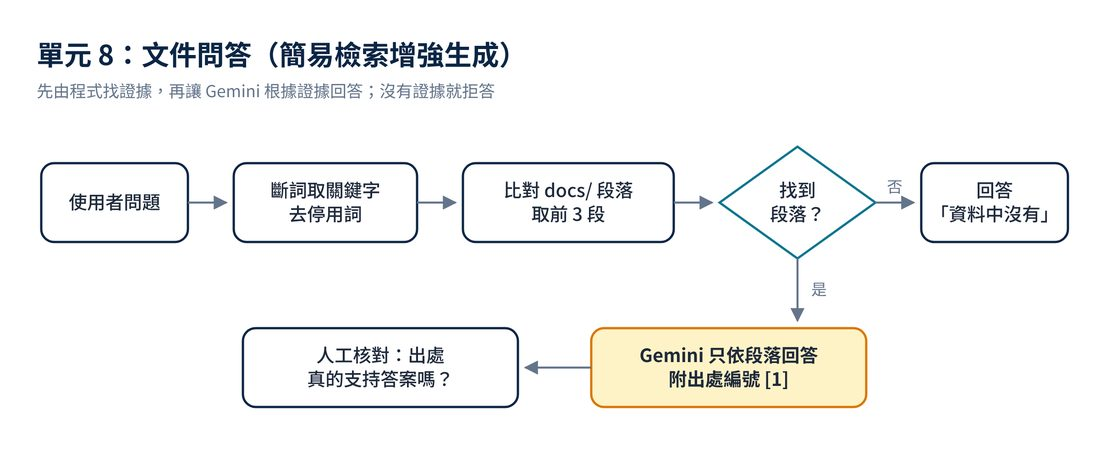

**CRISP 提示卡**（已經寫在程式的 prompt 裡）

```
R 角色：回答對象是大一新生，三句以內。
I 任務：只根據找到的段落回答，句尾標出處編號 [1]。
P 驗證：資料不夠就回答「資料中沒有」。
```

In [ ]:
#@title I＋S：先找段落，再請 Gemini 回答
docs = []
for path in glob.glob("docs/*.txt"):
    for para in open(path, encoding="utf-8").read().split("\n\n"):
        if para.strip():
            docs.append({"source": os.path.basename(path), "text": para.strip()})

def retrieve(q, k=3):
    qw = {w for w in jieba.lcut(q) if len(w) >= 2 and w not in stop}
    scored = [(len(qw & set(jieba.lcut(d["text"]))), d) for d in docs]
    scored = sorted([x for x in scored if x[0] > 0], key=lambda x: -x[0])
    return [d for _, d in scored[:k]]

def ask(q):
    hits = retrieve(q)
    if not hits:
        return "資料中沒有", []
    context = "\n".join(f"[{i+1}]（{d['source']}）{d['text']}" for i, d in enumerate(hits))
    ans = ask_gemini(f"""只根據下列資料回答，三句以內，句尾標出處編號如 [1]。
資料不足就回答「資料中沒有」。
資料：
{context}
問題：{q}""")
    return (ans or "（Gemini 不能用，下面是找到的段落）" + context), [d["source"] for d in hits]

answer, sources = ask("期中考是哪一週？")
print(answer, sources)

In [ ]:
#@title P 驗證：問幾題，包含資料裡沒有的
#@markdown **my_question** 你想問的問題
my_question = "作業遲交會怎樣？" #@param {type:"string"}
tests = [my_question, "期中考考哪些範圍？", "學校游泳池幾點開？"]   # 最後一題資料裡沒有
for q in tests:
    a, src = ask(q)
    print("問：", q)
    print("答：", a)
    print("出處：", src if src else "（沒有）")
    print("-" * 30)

**想一想**：每個答案都有出處嗎？出處的段落真的支持答案嗎？問「游泳池」時，它有老實說「資料中沒有」嗎？

**期末專題可以選**：課程 FAQ 問答、病蟲害描述查詢、水質報告摘要，或自選（先跟老師討論）。

In [ ]:
#@title 📝 監督日誌：第 8 關（填右邊的格子，再按 ▶）
#@markdown **my_prompt** 我給 Gemini 的提示｜**ai_did** Gemini 做了什麼｜**decision** 我的決定｜**reason** 理由
my_prompt = "" #@param {type:"string"}
ai_did = "" #@param {type:"string"}
decision = "採納" #@param ["採納", "修改", "退回"]
reason = "" #@param {type:"string"}
write_log("第 8 關", my_prompt, ai_did, decision, reason)

## 進階（選用）：用自己的 Gemini API 金鑰

一般上課用 `ask_gemini()` 就夠了。想用更新的模型或更大的用量，才需要自己的金鑰。

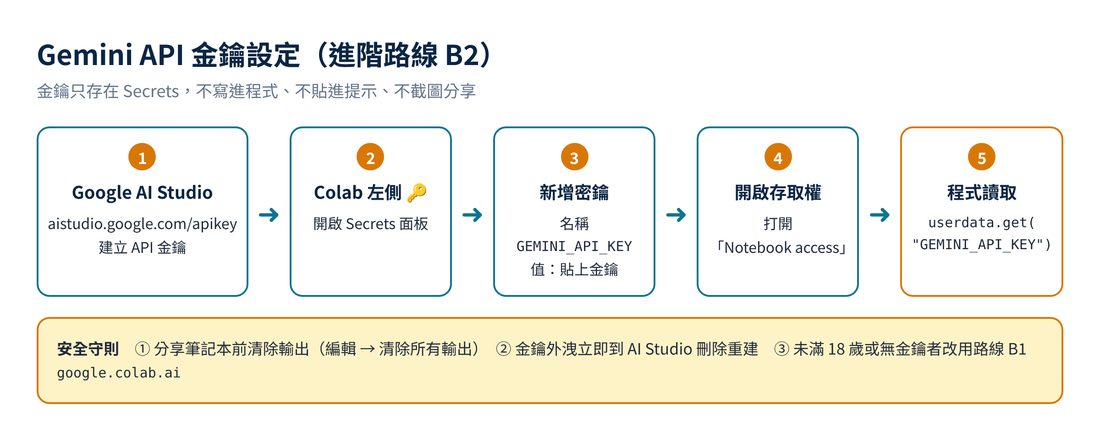

模型名稱依 Gemini API 文件 2026 年 10 月的範例，之後可能會更新，以官方模型頁為準。

In [ ]:
#@title 進階：用 API 金鑰呼叫 Gemini（金鑰存在左側 🔑 Secrets，名稱 GEMINI_API_KEY）
!pip install -q -U google-genai
from google import genai
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
r = client.interactions.create(model="gemini-3.8-flash",
                               input="用一句話說明什麼是中文斷詞")
print(r.output_text)

## 交作業

**檢查清單**

- [ ] 心智圖、IPO 已上傳並顯示
- [ ] 第 1–8 關都按過 ▶，看得到結果
- [ ] 每一關都填了監督日誌（log.csv）
- [ ] 分享前：編輯 → 清除所有輸出（作業要附輸出時，改用下面的打包檔）

按下面這格，會把你的成果打包成 my_work.zip 下載。筆記本本身另外用 **檔案 → 下載 → 下載 .ipynb** 存一份。

In [ ]:
#@title 打包下載我的成果
import zipfile
keep = [f for f in os.listdir(".")
        if f.lower().endswith((".csv", ".png", ".jpg", ".jpeg", ".json", ".txt")) and f != "dict.txt.big"]
with zipfile.ZipFile("my_work.zip", "w") as z:
    for f in keep:
        z.write(f)
print("打包了：", keep)
from google.colab import files
files.download("my_work.zip")

## 影片總表：看完要動手做什麼

V1–V7 是本課程自製影片，V8–V12 是外部教學影片；畫面可能和現在的 Colab 不太一樣，操作以這本筆記本為準。

| # | 影片 | 長度 | 對應 | 看完動手做 |
|---|---|---|---|---|
| [V1](https://youtu.be/yXTW5BtXPvQ) | 先思考後驗證 120秒影音（英配雙語字幕） | 1:59 | 課程導論 | 看完用一句話寫下「先思考」和「後驗證」各要做什麼 |
| [V2](https://youtu.be/jtSpZbgRm5g) | 由作而管：人機協作三層級（150秒精簡版） | 2:25 | 課程導論 | 看完想想：這本筆記本哪幾格是你「做」，哪幾格是你「管」？記一筆監督日誌 |
| [V3](https://youtu.be/l5luM0T6CfM) | paul@CT&GEN AI COLAB | 0:58 | 課前準備 | 看完按「第 0 步」的 ▶，確認工具裝好 |
| [V4](https://youtu.be/RgvnGZE6dMY) | 心智圖 IPO 教學影片（120秒） | 2:01 | 單元 2 | 跟著畫「課程回饋分析」心智圖，拍照上傳到「動手前」 |
| [V5](https://youtu.be/_Pda5WXIGpI) | 由 IPO 架構到 Python 運作之 AI Video | 0:56 | 單元 2 | 看完把 IPO 填進表單，按 ▶ 產生 CRISP 提示 |
| [V6](https://youtu.be/O5Vdxg89dNE) | Smart Aquaculture Tutorial（180s） | 3:01 | 單元 3 魚塭案例 | 把溶氧、水溫當 I，警示當 O，對照第 3 關的 alert() |
| [V7](https://youtu.be/glkNRqyLSio) | 基於 ROUGE 指標評估生成式 AI 模型之偏差與雜訊 | 0:56 | 單元 7 | 想想除了「重點句在原文」，還能怎麼檢查摘要 |
| [V8](https://youtu.be/inN8seMm7UI) | Get started with Google Colaboratory（TensorFlow，英文） | 3:10 | 課前準備 | 跟著新增一格程式碼、一格文字 |
| [V9](https://youtu.be/eJCXFIoOwdw) | Python 第一課：Google Colaboratory 介紹（DataSci Ocean） | 23:40 | 課前準備 | 04:23 開啟 Colab｜05:44 執行程式｜06:51 介面｜17:33 快捷鍵 |
| [V10](https://youtu.be/XWJzlzMaG1k) | How to Use Google Gemini in Google Colab for FREE（Valley4Techs，英文） | 4:17 | 課前準備／單元 1 | 打開 Gemini 面板，貼上第 1 關提示卡，請它先說做法 |
| [V11](https://youtu.be/mUYWpvAncjk) | 在 Google Colab 上設定 Gemini 與操作 Python（An-Wen Deng） | 16:53 | 單元 5、7 | 比較影片寫法和本筆記本的 ask_gemini()（這裡不用金鑰） |
| [V12](https://youtu.be/zrKyTYQqH-s) | 5 分鐘在 Colab 快速使用 Gemini 來產生文本（李政軒） | 8:19 | 單元 7（舊版套件） | 影片用舊套件；練習時改用「進階」那格的 google-genai 寫法 |

課程頻道：[youtube.com/@paulkuo4106](https://www.youtube.com/@paulkuo4106)　短網址：[pjkuo.github.io/yt](https://pjkuo.github.io/yt)